**CMSE 830 Midterm Project, Fall 2026** | Shubham Koirala

In this notebook, i prepared data for IDA, EDA and the app. I am sourcing data from OCTAD 2.0, my own resource that i am building for my dissertation. Not all data can be shared due to two major reasons. First, its large, almost around 2 GB. Second, its under review right now, which will lead to publication. So for the midterm, I change the formatting and make it concise so that i can demonstrate accordingly.

# 01 Data Preparation

Turned the raw OCTAD 2.0 data (7.3 million rows and almost 1.8 GB) into four small files that EDA and app notebook use. Runs quickly and reads the file in chunks.

**Input:** one CSV with the per disease `*_meta.csv` files stacked and a leading `disease` column (or the folder of `*_meta.csv` files).
**Output:** `data/processed/` with `disease_summary.csv`, `top_genes.csv`, `gene_sample.csv`, `audit.json`.

In [39]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# path to where your combined file are
INPUT = Path("../../all_meta_combined.csv")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

In [40]:
SEED = 830            # random sample seed
SAMPLE_FRAC = 0.03    # share of all gene rows kept for catalog wide EDA
TOP_N = 150           # strongest genes kept per disease and direction
COLS = ["gene_symbol", "log2FoldChange_meta", "se_meta", "pval_meta", "padj_meta", "I2", "k_datasets"]

In [41]:
# Helper functions
def tier(k):
    """Confidence tier from the number of supporting datasets: low = 1, medium = 2 to 5, high = 6 or more."""
    return np.where(k <= 1, "low", np.where(k <= 5, "medium", "high"))


def iter_diseases(path: Path):
    """Yield (disease, DataFrame) one disease at a time, never holding the whole file in memory."""
    if path.is_dir():
        for f in sorted(path.glob("*_meta.csv")):
            yield f.name[: -len("_meta.csv")], pd.read_csv(f, usecols=COLS)
        return
    cur, buf = None, []
    for chunk in pd.read_csv(path, usecols=["disease"] + COLS, chunksize=1_000_000):
        for name, g in chunk.groupby("disease", sort=False):
            if cur is not None and name != cur:
                yield cur, pd.concat(buf).drop(columns="disease")
                buf = []
            cur = name
            buf.append(g)
    yield cur, pd.concat(buf).drop(columns="disease")


def top_genes(df, disease, n=TOP_N):
    """Top n genes per direction, ranked by adjusted p, then raw p, then larger |log2FC| (many adjusted p are exactly 0)."""
    d = df.dropna(subset=["log2FoldChange_meta", "padj_meta"]).copy()
    d["abs_lfc"] = d["log2FoldChange_meta"].abs()
    d = d.sort_values(["padj_meta", "pval_meta", "abs_lfc"], ascending=[True, True, False])
    parts = [d[d["log2FoldChange_meta"] > 0].head(n).assign(direction="up"),
             d[d["log2FoldChange_meta"] < 0].head(n).assign(direction="down")]
    out = pd.concat(parts)
    out.insert(0, "disease", disease)
    return out.drop(columns="abs_lfc")

### Check over the disease

For each disease this loop does three things:
1. Audit: adds to running counts of missing values, `padj = 0`, extreme fold changes, duplicate symbols and tier sizes.
2. Fix I²: OCTAD reports I² = 0 for single dataset genes, but disagreement cannot be measured from one study, so I² is set to missing when k is 1.
3. Keeps a one row summary, the strongest genes, and a 3% random sample of rows.

In [42]:
rng = np.random.default_rng(SEED)
summary, tops, samples = [], [], []
A = dict(rows=0, diseases=0, na={c: 0 for c in COLS}, padj_zero=0, padj_zero_and_p_zero=0, padj_below_p=0,
         abs_lfc_gt10=0, abs_lfc_gt10_k1=0, dup_symbol_rows=0, k1_rows=0, k1_i2_zero=0, padj_na_k1=0,
         padj_na_k2plus=0, k2_5_rows=0, k6_rows=0, sig_rows=0, sig_k1=0)

for disease, df in iter_diseases(INPUT):
    A["diseases"] += 1
    A["rows"] += len(df)
    for c in COLS:
        A["na"][c] += int(df[c].isna().sum())
    k = df["k_datasets"]
    p0 = df["padj_meta"] == 0
    A["padj_zero"] += int(p0.sum())
    A["padj_zero_and_p_zero"] += int((p0 & (df["pval_meta"] == 0)).sum())
    A["padj_below_p"] += int((df["padj_meta"] < df["pval_meta"]).sum())
    big = df["log2FoldChange_meta"].abs() > 10
    A["abs_lfc_gt10"] += int(big.sum())
    A["abs_lfc_gt10_k1"] += int((big & (k == 1)).sum())
    A["dup_symbol_rows"] += int(df.duplicated(subset="gene_symbol", keep=False).sum())
    A["k1_rows"] += int((k == 1).sum())
    A["padj_na_k1"] += int((df["padj_meta"].isna() & (k == 1)).sum())
    A["padj_na_k2plus"] += int((df["padj_meta"].isna() & (k >= 2)).sum())
    A["k1_i2_zero"] += int(((k == 1) & (df["I2"] == 0)).sum())
    A["k2_5_rows"] += int(((k >= 2) & (k <= 5)).sum())
    A["k6_rows"] += int((k >= 6).sum())

    df = df.assign(I2=df["I2"].where(k >= 2))          # I2 is not measurable from one dataset

    sig = df["padj_meta"] < 0.05
    A["sig_rows"] += int(sig.sum())
    A["sig_k1"] += int((sig & (k == 1)).sum())
    rep = sig & (k >= 2)
    summary.append(dict(
        disease=disease, n_genes=len(df), n_sig=int(sig.sum()), n_sig_replicated=int(rep.sum()),
        share_sig_replicated=(rep.sum() / sig.sum()) if sig.sum() else np.nan,
        pct_genes_untested=float(df["padj_meta"].isna().mean() * 100),
        k_max=int(k.max()), k_median=float(k.median()),
        pct_genes_k1=float((k == 1).mean() * 100), pct_genes_k6plus=float((k >= 6).mean() * 100),
        median_I2_k2plus=float(df.loc[k >= 2, "I2"].median()) if (k >= 2).any() else np.nan,
        median_abs_lfc_sig=float(df.loc[sig, "log2FoldChange_meta"].abs().median()) if sig.any() else np.nan,
    ))
    df = df.reset_index(drop=True)
    tops.append(top_genes(df, disease))
    samples.append(df.sample(frac=SAMPLE_FRAC, random_state=int(rng.integers(1_000_000_000))).assign(disease=disease))

print(f"{A['diseases']} diseases, {A['rows']:,} rows processed")

350 diseases, 7,273,417 rows processed


### Write the output files (input files for IDA, EDA and app)

In [43]:
ds = pd.DataFrame(summary)
ds["tier"] = tier(ds["k_max"].to_numpy())
ds.to_csv(OUT / "disease_summary.csv", index=False, float_format="%.6g")

pd.concat(tops).drop(columns=["se_meta"]).to_csv(OUT / "top_genes.csv", index=False, float_format="%.6g")

gs = pd.concat(samples).dropna(subset=["log2FoldChange_meta", "padj_meta"])      # untested genes are left out of the sample
gs["direction"] = np.where(gs["log2FoldChange_meta"] > 0, "up", "down")
gs = gs[["disease", "gene_symbol", "direction", "log2FoldChange_meta", "pval_meta", "padj_meta", "I2", "k_datasets"]]
gs.to_csv(OUT / "gene_sample.csv", index=False, float_format="%.6g")

A.update(sample_rows=len(gs), sample_fraction=SAMPLE_FRAC, seed=SEED, tier_counts_diseases=ds["tier"].value_counts().to_dict())
(OUT / "audit.json").write_text(json.dumps(A, indent=2))

for f in sorted(OUT.glob("*")):
    print(f"{f.name:22s} {f.stat().st_size / 1e6:6.1f} MB")

.ipynb_checkpoints        0.0 MB
audit.json                0.0 MB
disease_summary.csv       0.0 MB
gene_sample.csv          13.4 MB
top_genes.csv             7.1 MB


### Sanity checks

In [44]:
assert A["diseases"] == 350, "expected 350 diseases"
assert ds["disease"].is_unique
assert (pd.read_csv(OUT / "top_genes.csv").groupby("disease").size() <= 2 * TOP_N).all()
assert A["padj_na_k2plus"] == 0 or True   # informational: missing p-values only among single dataset genes when 0
print("Missing adjusted p only in single dataset genes:", A["padj_na_k2plus"] == 0)
print("Tier counts (diseases):", A["tier_counts_diseases"])
ds.head()

Missing adjusted p only in single dataset genes: True
Tier counts (diseases): {'low': 213, 'high': 123, 'medium': 14}


,disease,n_genes,n_sig,n_sig_replicated,share_sig_replicated,pct_genes_untested,k_max,k_median,pct_genes_k1,pct_genes_k6plus,median_I2_k2plus,median_abs_lfc_sig,tier
0,Abortion-Habitual,17736,6304,0,0.0,0.0,1,1.0,100.0,0.0,NaN,2.160753,low
1,Acromegaly,18206,1560,0,0.0,0.0,1,1.0,100.0,0.0,NaN,2.502592,low
2,Acute-Cellular-Rejection,18565,7772,0,0.0,0.0,1,1.0,100.0,0.0,NaN,0.599405,low
3,Acute-Kidney-Injury,17113,951,0,0.0,0.0,1,1.0,100.0,0.0,NaN,2.019132,low
4,Acute-Lung-Injury,19007,87,0,0.0,0.0,1,1.0,100.0,0.0,NaN,2.062721,low


### Visual checks

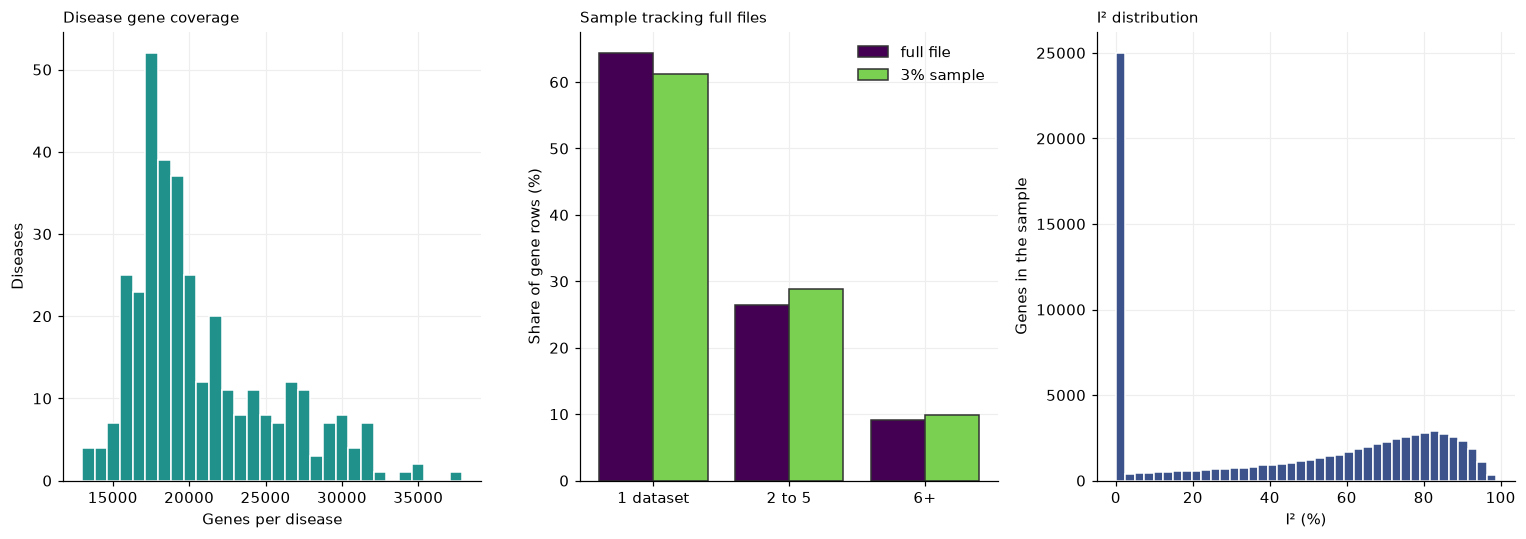

In [45]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#eeeeee", "axes.axisbelow": True})
fig, ax = plt.subplots(1, 3, figsize=(14, 5))

# 1. every disease is present and has a plausible number of genes
ax[0].hist(ds["n_genes"], bins=30, color="#21918c", edgecolor="white")
ax[0].set_xlabel("Genes per disease"); ax[0].set_ylabel("Diseases")
ax[0].set_title("Disease gene coverage", fontsize=10, loc="left")

# 2. the 3% sample should look like the full file (the sample leaves out untested genes, so expect a small gap)
full = pd.Series({"low": A["k1_rows"], "medium": A["k2_5_rows"], "high": A["k6_rows"]}) / A["rows"] * 100
samp = pd.cut(gs["k_datasets"], [0, 1, 5, np.inf], labels=["low", "medium", "high"]).value_counts(normalize=True).reindex(["low", "medium", "high"]) * 100
x = np.arange(3)
ax[1].bar(x - 0.2, full, 0.4, label="full file", color="#440154", edgecolor="#333")
ax[1].bar(x + 0.2, samp, 0.4, label="3% sample", color="#7ad151", edgecolor="#333")
ax[1].set_xticks(x); ax[1].set_xticklabels(["1 dataset", "2 to 5", "6+"]); ax[1].set_ylabel("Share of gene rows (%)")
ax[1].legend(frameon=False); ax[1].set_title("Sample tracking full files", fontsize=10, loc="left")

# 3. I2 after the fix: missing for single dataset genes, a real distribution for the rest
vals = gs["I2"].dropna()
ax[2].hist(vals, bins=40, color="#3b528b", edgecolor="white")
ax[2].set_xlabel("I² (%)"); ax[2].set_ylabel("Genes in the sample")
ax[2].set_title("I² distribution", fontsize=10, loc="left")
plt.tight_layout(); plt.show()